# 08. Null Models and Research Answers

This notebook answers RQ4 with label shuffling and degree-preserving rewiring, compares the observed graph with standard random graph families, and consolidates the four research answers.


In [1]:
from pathlib import Path
import os
import sys
import warnings

import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display


def find_project_root(start: Path) -> Path:
    """Find the repository root whether Jupyter starts there or in notebooks/."""
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root.")


ROOT = find_project_root(Path.cwd())
os.chdir(ROOT)
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
print(f"Project root: {ROOT}")


Project root: C:\Users\Jimi\Desktop\github-social-network


## Null-model logic and empirical p-values

The label-shuffle null keeps the graph and class counts fixed while permuting labels. The degree-preserving null keeps labels and every node degree fixed while repeatedly applying double-edge swaps. Louvain is rerun on each rewired graph.

```text
observed = statistic(real graph)
for b in 1..B:
    null[b] = statistic(randomized graph or labels)
empirical upper-tail p = (1 + count(null >= observed)) / (B + 1)
```

The `+1` correction prevents a simulated p-value of zero. The experiment uses 1,000 label shuffles and 20 degree-preserving rewired graphs. A benchmark showed that one full rewire plus Louvain pass takes about 21 seconds on the execution machine, so 99 rewired graphs were not practical for the complete reproducibility run. With 20 samples, the smallest possible empirical p-value is `1/21 = 0.0476`. This permits only a coarse upper-tail conclusion.


### Production implementation: null statistics and empirical p-values

This first part of src/run_null_models.py defines the null-model settings and the statistics used for comparison: same-label edge fraction, sampled average shortest-path length, and an empirical upper-tail p-value with a finite-simulation correction. The functions receive vectorized edge endpoints and labels or a graph and random generator, and return scalar statistics. Their empty-case checks and exact sampling rules make clear how the observed network is compared with simulated label and topology nulls.


In [2]:
"""
Null models and statistical significance of the structural findings.

Three questions, each answered against an appropriate random model:

1. Is the observed homophily (share of same-label edges) significant?
   - Null A: shuffle labels over nodes (1,000 permutations, degree structure
     and label counts preserved).
   - Null B: degree-preserving edge rewiring (double edge swaps, labels
     fixed) - controls for the degree-label correlation.

2. Is the Louvain modularity significant?
   - Compared against Louvain modularity of degree-preserving rewired graphs.

3. Which properties are reproduced by course-covered network models?
   - Erdos-Renyi, Barabasi-Albert, Watts-Strogatz small-world and a
     degree-preserving configuration-style null graph.
   - Power-law fit of the degree distribution (powerlaw package), including
     likelihood-ratio comparison against lognormal and exponential.

Outputs:
    outputs/tables/null_model_homophily.csv
    outputs/tables/null_model_modularity.csv
    outputs/tables/network_vs_random_models.csv
    outputs/tables/powerlaw_fit.csv
    outputs/figures/homophily_null_distribution.png
    outputs/figures/degree_distribution_loglog.png
"""
import time
from pathlib import Path

import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

SRC_DIR = ROOT / "src"
PROJECT_DIR = ROOT
sys.path.insert(0, str(SRC_DIR))

from community_analysis import detect_louvain_communities
from data_loader import load_dataset


N_LABEL_SHUFFLES = 1000
N_REWIRES = 20
N_SWAPS_PER_EDGE = 2
N_BFS_SAMPLES = 300
SEED = 42
SMALL_WORLD_REWIRING_PROBABILITY = 0.10


def same_label_fraction(edge_u: np.ndarray, edge_v: np.ndarray, labels: np.ndarray) -> float:
    """Fraction of edges whose endpoints share a label."""
    return float(np.mean(labels[edge_u] == labels[edge_v]))


def sampled_average_shortest_path(G: nx.Graph, n_samples: int, rng: np.random.Generator) -> float:
    """Estimate average shortest path length via BFS from sampled sources."""
    nodes = list(G.nodes())
    sources = rng.choice(len(nodes), size=min(n_samples, len(nodes)), replace=False)
    total, count = 0.0, 0
    for idx in sources:
        lengths = nx.single_source_shortest_path_length(G, nodes[int(idx)])
        # exclude the source itself
        total += sum(lengths.values())
        count += len(lengths) - 1
    return total / count if count else float("nan")


def empirical_upper_tail_p(
    null_values: np.ndarray, observed_value: float
) -> float:
    """Finite-simulation upper-tail p-value with the (b+1)/(B+1) correction."""
    values = np.asarray(null_values, dtype=float)
    if values.size == 0:
        raise ValueError("At least one null simulation is required.")
    return float((np.sum(values >= observed_value) + 1) / (values.size + 1))



In [3]:
from run_null_models import N_REWIRES, empirical_upper_tail_p

minimum_rewire_p = empirical_upper_tail_p(np.zeros(N_REWIRES), observed_value=1.0)
display(pd.DataFrame([{
    "degree_preserving_samples": N_REWIRES,
    "smallest_empirical_p": minimum_rewire_p,
}]))
assert N_REWIRES == 20
assert np.isclose(minimum_rewire_p, 1 / 21)


,degree_preserving_samples,smallest_empirical_p
0,20,0.047619


### Production implementation: label-shuffle and degree-preserving null experiments

This cell reproduces the complete main null-model workflow from src/run_null_models.py. It loads the graph, repeatedly shuffles labels for the homophily null, repeatedly applies connected double-edge swaps for the degree-preserving topology null, computes empirical p-values and z-scores, and saves tables and histograms. The retry logic, seeded simulation loops, connectivity check, swap budget, observed statistics, and plot annotations are shown because they determine the strength and validity of the statistical conclusions.


In [4]:
def main() -> None:
    data_dir = PROJECT_DIR / "data"
    tables_dir = PROJECT_DIR / "outputs" / "tables"
    figures_dir = PROJECT_DIR / "outputs" / "figures"
    tables_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    G, edges_df, labels_df, labels_dict = load_dataset(data_dir)
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()

    labels = np.zeros(int(labels_df["id"].max()) + 1, dtype=np.int64)
    labels[labels_df["id"].to_numpy()] = labels_df["label"].to_numpy()
    edge_u = edges_df["id_1"].to_numpy(dtype=np.int64)
    edge_v = edges_df["id_2"].to_numpy(dtype=np.int64)

    rng = np.random.default_rng(SEED)

    # ------------------------------------------------------------------
    # 1) Homophily significance
    # ------------------------------------------------------------------
    observed_fraction = same_label_fraction(edge_u, edge_v, labels)
    observed_assortativity = nx.attribute_assortativity_coefficient(G, "label")
    print(f"Observed same-label fraction: {observed_fraction:.4f}")
    print(f"Observed label assortativity: {observed_assortativity:.4f}")

    # Null A: label shuffling
    print(f"Null A: {N_LABEL_SHUFFLES} label shuffles ...")
    t0 = time.time()
    shuffle_fractions = np.empty(N_LABEL_SHUFFLES)
    label_pool = labels_df["label"].to_numpy().copy()
    node_ids = labels_df["id"].to_numpy()
    for i in range(N_LABEL_SHUFFLES):
        shuffled = rng.permutation(label_pool)
        null_labels = np.zeros_like(labels)
        null_labels[node_ids] = shuffled
        shuffle_fractions[i] = same_label_fraction(edge_u, edge_v, null_labels)
    print(f"  done in {time.time() - t0:.1f}s")

    shuffle_mean = float(shuffle_fractions.mean())
    shuffle_std = float(shuffle_fractions.std(ddof=1))
    z_shuffle = (observed_fraction - shuffle_mean) / shuffle_std
    # Empirical p with the (b+1)/(B+1) correction: an empirical p-value can
    # never be exactly 0, only bounded by the number of permutations.
    p_shuffle = empirical_upper_tail_p(shuffle_fractions, observed_fraction)

    # Null B: degree-preserving rewiring (labels fixed)
    print(f"Null B: {N_REWIRES} degree-preserving rewired graphs ...")
    rewire_fractions = []
    rewire_modularities = []
    G_configuration = None
    for i in range(N_REWIRES):
        t0 = time.time()
        G_rewired = G.copy()
        nx.connected_double_edge_swap(
            G_rewired,
            nswap=n_edges * N_SWAPS_PER_EDGE,
            seed=SEED + i,
        )
        assert nx.is_connected(G_rewired)
        if i == 0:
            # Simple-graph configuration-style null: exact degrees are
            # retained while the endpoint pairing is randomized.
            G_configuration = G_rewired.copy()

        rewired_edges = np.array(G_rewired.edges(), dtype=np.int64)
        rewire_fractions.append(
            same_label_fraction(rewired_edges[:, 0], rewired_edges[:, 1], labels)
        )

        _, modularity = detect_louvain_communities(G_rewired, random_state=42)
        rewire_modularities.append(float(modularity))
        print(
            f"  rewire {i + 1}/{N_REWIRES}: same-label={rewire_fractions[-1]:.4f}, "
            f"modularity={rewire_modularities[-1]:.4f} ({time.time() - t0:.0f}s)"
        )

    rewire_fractions_arr = np.asarray(rewire_fractions)
    rewire_mean = float(rewire_fractions_arr.mean())
    rewire_std = float(rewire_fractions_arr.std(ddof=1))
    z_rewire = (observed_fraction - rewire_mean) / rewire_std if rewire_std else float("inf")

    homophily_df = pd.DataFrame(
        [
            {
                "null_model": "label_shuffle",
                "n_samples": N_LABEL_SHUFFLES,
                "observed": observed_fraction,
                "null_mean": shuffle_mean,
                "null_std": shuffle_std,
                "z_score": z_shuffle,
                "empirical_p": p_shuffle,
            },
            {
                "null_model": "degree_preserving_rewire",
                "n_samples": N_REWIRES,
                "observed": observed_fraction,
                "null_mean": rewire_mean,
                "null_std": rewire_std,
                "z_score": z_rewire,
                "empirical_p": empirical_upper_tail_p(
                    rewire_fractions_arr, observed_fraction
                ),
            },
        ]
    )
    homophily_df.to_csv(tables_dir / "null_model_homophily.csv", index=False)

    # ------------------------------------------------------------------
    # 2) Modularity significance
    # ------------------------------------------------------------------
    _, observed_modularity = detect_louvain_communities(G, random_state=42)
    rewire_mod_arr = np.asarray(rewire_modularities)
    mod_mean = float(rewire_mod_arr.mean())
    mod_std = float(rewire_mod_arr.std(ddof=1))
    z_modularity = (observed_modularity - mod_mean) / mod_std if mod_std else float("inf")

    modularity_df = pd.DataFrame(
        [
            {
                "observed_modularity": float(observed_modularity),
                "rewired_null_mean": mod_mean,
                "rewired_null_std": mod_std,
                "z_score": z_modularity,
                "n_rewires": N_REWIRES,
                "empirical_p": empirical_upper_tail_p(
                    rewire_mod_arr, observed_modularity
                ),
            }
        ]
    )
    modularity_df.to_csv(tables_dir / "null_model_modularity.csv", index=False)
    print(f"Modularity: observed={observed_modularity:.4f}, rewired null={mod_mean:.4f} (z={z_modularity:.1f})")

    # ------------------------------------------------------------------
    # 3) GitHub vs classical random models
    # ------------------------------------------------------------------
    print("Building course-covered comparison graphs ...")
    # ER matches the edge count exactly; BA with integer m=8 yields ~301.5K
    # edges (about 4% more than the real network), so it is comparable in
    # size but not identical.
    ba_m = max(1, round(n_edges / n_nodes))
    small_world_k = max(2, 2 * round((2 * n_edges / n_nodes) / 2))
    G_er = nx.gnm_random_graph(n_nodes, n_edges, seed=SEED)
    G_ba = nx.barabasi_albert_graph(n_nodes, ba_m, seed=SEED)
    G_small_world = nx.watts_strogatz_graph(
        n_nodes,
        small_world_k,
        SMALL_WORLD_REWIRING_PROBABILITY,
        seed=SEED,
    )
    if G_configuration is None:
        raise AssertionError("Configuration-style null graph was not created.")

    rows = []
    comparison_graphs = (
        ("GitHub observed", G),
        ("Erdos-Renyi", G_er),
        (f"Barabasi-Albert (m={ba_m})", G_ba),
        (
            f"Watts-Strogatz (k={small_world_k}, p={SMALL_WORLD_REWIRING_PROBABILITY})",
            G_small_world,
        ),
        ("Degree-preserving configuration null", G_configuration),
    )
    for name, graph in comparison_graphs:
        t0 = time.time()
        degrees = np.array([d for _, d in graph.degree()])
        largest_cc = graph.subgraph(max(nx.connected_components(graph), key=len))
        rows.append(
            {
                "network": name,
                "nodes": graph.number_of_nodes(),
                "edges": graph.number_of_edges(),
                "edge_count_difference_pct": float(
                    100 * (graph.number_of_edges() - n_edges) / n_edges
                ),
                "max_degree": int(degrees.max()),
                "mean_degree": float(degrees.mean()),
                "transitivity": float(nx.transitivity(graph)),
                "avg_clustering": float(nx.average_clustering(graph)),
                "degree_assortativity": float(nx.degree_assortativity_coefficient(graph)),
                "avg_shortest_path_sampled": sampled_average_shortest_path(
                    largest_cc, N_BFS_SAMPLES, rng
                ),
            }
        )
        print(f"  {name} done ({time.time() - t0:.0f}s)")

    comparison_df = pd.DataFrame(rows)
    comparison_df.to_csv(tables_dir / "network_vs_random_models.csv", index=False)
    print(comparison_df.to_string(index=False))

    # Power-law fit
    print("Fitting power law to the degree distribution ...")
    import warnings

    import powerlaw

    github_degrees = np.array([d for _, d in G.degree()])
    with warnings.catch_warnings():
        # powerlaw emits a benign internal warning while exploring lognormal fits
        warnings.filterwarnings("ignore", message="No valid fits found")
        fit = powerlaw.Fit(github_degrees, discrete=True, verbose=False)
        lr_lognormal, p_lognormal = fit.distribution_compare("power_law", "lognormal")
        lr_exponential, p_exponential = fit.distribution_compare("power_law", "exponential")

    powerlaw_df = pd.DataFrame(
        [
            {
                "alpha": float(fit.power_law.alpha),
                "xmin": float(fit.power_law.xmin),
                "sigma": float(fit.power_law.sigma),
                "loglik_ratio_vs_lognormal": float(lr_lognormal),
                "p_vs_lognormal": float(p_lognormal),
                "loglik_ratio_vs_exponential": float(lr_exponential),
                "p_vs_exponential": float(p_exponential),
            }
        ]
    )
    powerlaw_df.to_csv(tables_dir / "powerlaw_fit.csv", index=False)
    print(powerlaw_df.to_string(index=False))

    # ------------------------------------------------------------------
    # Figures
    # ------------------------------------------------------------------
    # Homophily null distribution
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].hist(shuffle_fractions, bins=40, color="#9bb7e0", edgecolor="white")
    axes[0].axvline(observed_fraction, color="#c0392b", linewidth=2,
                    label=f"Observed ({observed_fraction:.3f})")
    axes[0].set_title(f"Null A: Label Shuffle ({N_LABEL_SHUFFLES} permutations)\nz = {z_shuffle:.0f}")
    axes[0].set_xlabel("Same-label edge fraction")
    axes[0].set_ylabel("Count")
    axes[0].legend()

    axes[1].hist(rewire_fractions_arr, bins=10, color="#a8d5a2", edgecolor="white")
    axes[1].axvline(observed_fraction, color="#c0392b", linewidth=2,
                    label=f"Observed ({observed_fraction:.3f})")
    axes[1].set_title(f"Null B: Degree-Preserving Rewiring ({N_REWIRES} graphs)\nz = {z_rewire:.0f}")
    axes[1].set_xlabel("Same-label edge fraction")
    axes[1].legend()

    fig.suptitle("Observed homophily compared with two null models", fontsize=13)
    fig.tight_layout()
    fig.savefig(figures_dir / "homophily_null_distribution.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

    # Degree distribution log-log CCDF
    fig, ax = plt.subplots(figsize=(8, 6))
    for name, graph, color in (
        ("GitHub observed", G, "#315C8D"),
        ("Erdos-Renyi", G_er, "#8a8a8a"),
        (f"Barabasi-Albert (m={ba_m})", G_ba, "#D57837"),
        ("Watts-Strogatz", G_small_world, "#4F8A5B"),
        ("Degree-preserving null", G_configuration, "#7B5BA7"),
    ):
        degs = np.sort(np.array([d for _, d in graph.degree()]))
        ccdf = 1.0 - np.arange(1, len(degs) + 1) / len(degs)
        mask = (degs > 0) & (ccdf > 0)
        ax.loglog(degs[mask], ccdf[mask], marker=".", linestyle="none", markersize=3,
                  alpha=0.6, color=color, label=name)
    ax.set_xlabel("Degree k")
    ax.set_ylabel("P(K >= k)  (CCDF)")
    ax.set_title(
        f"Degree Distribution: GitHub vs Random Models\n"
        f"(power-law fit: alpha = {fit.power_law.alpha:.2f}, x_min = {fit.power_law.xmin:.0f})"
    )
    ax.legend()
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    fig.savefig(figures_dir / "degree_distribution_loglog.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

    print("Saved tables and figures.")



## Run the null models


In [5]:
from run_null_models import main as run_null_models

run_null_models()


Observed same-label fraction: 0.8453
Observed label assortativity: 0.3778
Null A: 1000 label shuffles ...


  done in 1.5s
Null B: 20 degree-preserving rewired graphs ...


  rewire 1/20: same-label=0.7513, modularity=0.1892 (301s)


  rewire 2/20: same-label=0.7520, modularity=0.1885 (328s)


  rewire 3/20: same-label=0.7530, modularity=0.1887 (337s)


...

  Barabasi-Albert (m=8) done (38s)


  Watts-Strogatz (k=16, p=0.1) done (44s)


  Degree-preserving configuration null done (85s)
                             network  nodes  edges  edge_count_difference_pct  max_degree  mean_degree  transitivity  avg_clustering  degree_assortativity  avg_shortest_path_sampled
                     GitHub observed  37700 289003                   0.000000        9458    15.331724      0.012357        0.167537             -0.075217                   3.217995
                         Erdos-Renyi  37700 289003                   0.000000          34    15.331724      0.000394        0.000396              0.001112                   4.125327
               Barabasi-Albert (m=8)  37700 301536                   4.336633         891    15.996605      0.002709        0.003378             -0.013764                   3.589527
        Watts-Strogatz (k=16, p=0.1)  37700 301600                   4.358778          22    16.000000      0.505876        0.511674             -0.004467                   5.551645
Degree-preserving configuration null  37

   alpha  xmin    sigma  loglik_ratio_vs_lognormal  p_vs_lognormal  loglik_ratio_vs_exponential  p_vs_exponential
2.544116  55.0 0.037774                   0.012701        0.782626                   605.791061      2.128203e-07


Saved tables and figures.


## Null-model results


,null_model,n_samples,observed,null_mean,null_std,z_score,empirical_p
0,label_shuffle,1000,0.845344,0.616599,0.011765,19.442172,0.000999
1,degree_preserving_rewire,20,0.845344,0.752309,0.000504,184.638669,0.047619


,observed_modularity,rewired_null_mean,rewired_null_std,z_score,n_rewires,empirical_p
0,0.453448,0.188373,0.000991,267.389533,20,0.047619


,network,nodes,edges,edge_count_difference_pct,max_degree,mean_degree,transitivity,avg_clustering,degree_assortativity,avg_shortest_path_sampled
0,GitHub observed,37700,289003,0.0000,9458,15.3317,0.0124,0.1675,-0.0752,3.2180
1,Erdos-Renyi,37700,289003,0.0000,34,15.3317,0.0004,0.0004,0.0011,4.1253
2,Barabasi-Albert (m=8),37700,301536,4.3366,891,15.9966,0.0027,0.0034,-0.0138,3.5895
3,"Watts-Strogatz (k=16, p=0.1)",37700,301600,4.3588,22,16.0000,0.5059,0.5117,-0.0045,5.5516
4,Degree-preserving configuration null,37700,289003,0.0000,9458,15.3317,0.0122,0.0924,-0.0713,3.1294


,alpha,xmin,sigma,loglik_ratio_vs_lognormal,p_vs_lognormal,loglik_ratio_vs_exponential,p_vs_exponential
0,2.5441,55.0,0.0378,0.0127,0.7826,605.7911,0.0


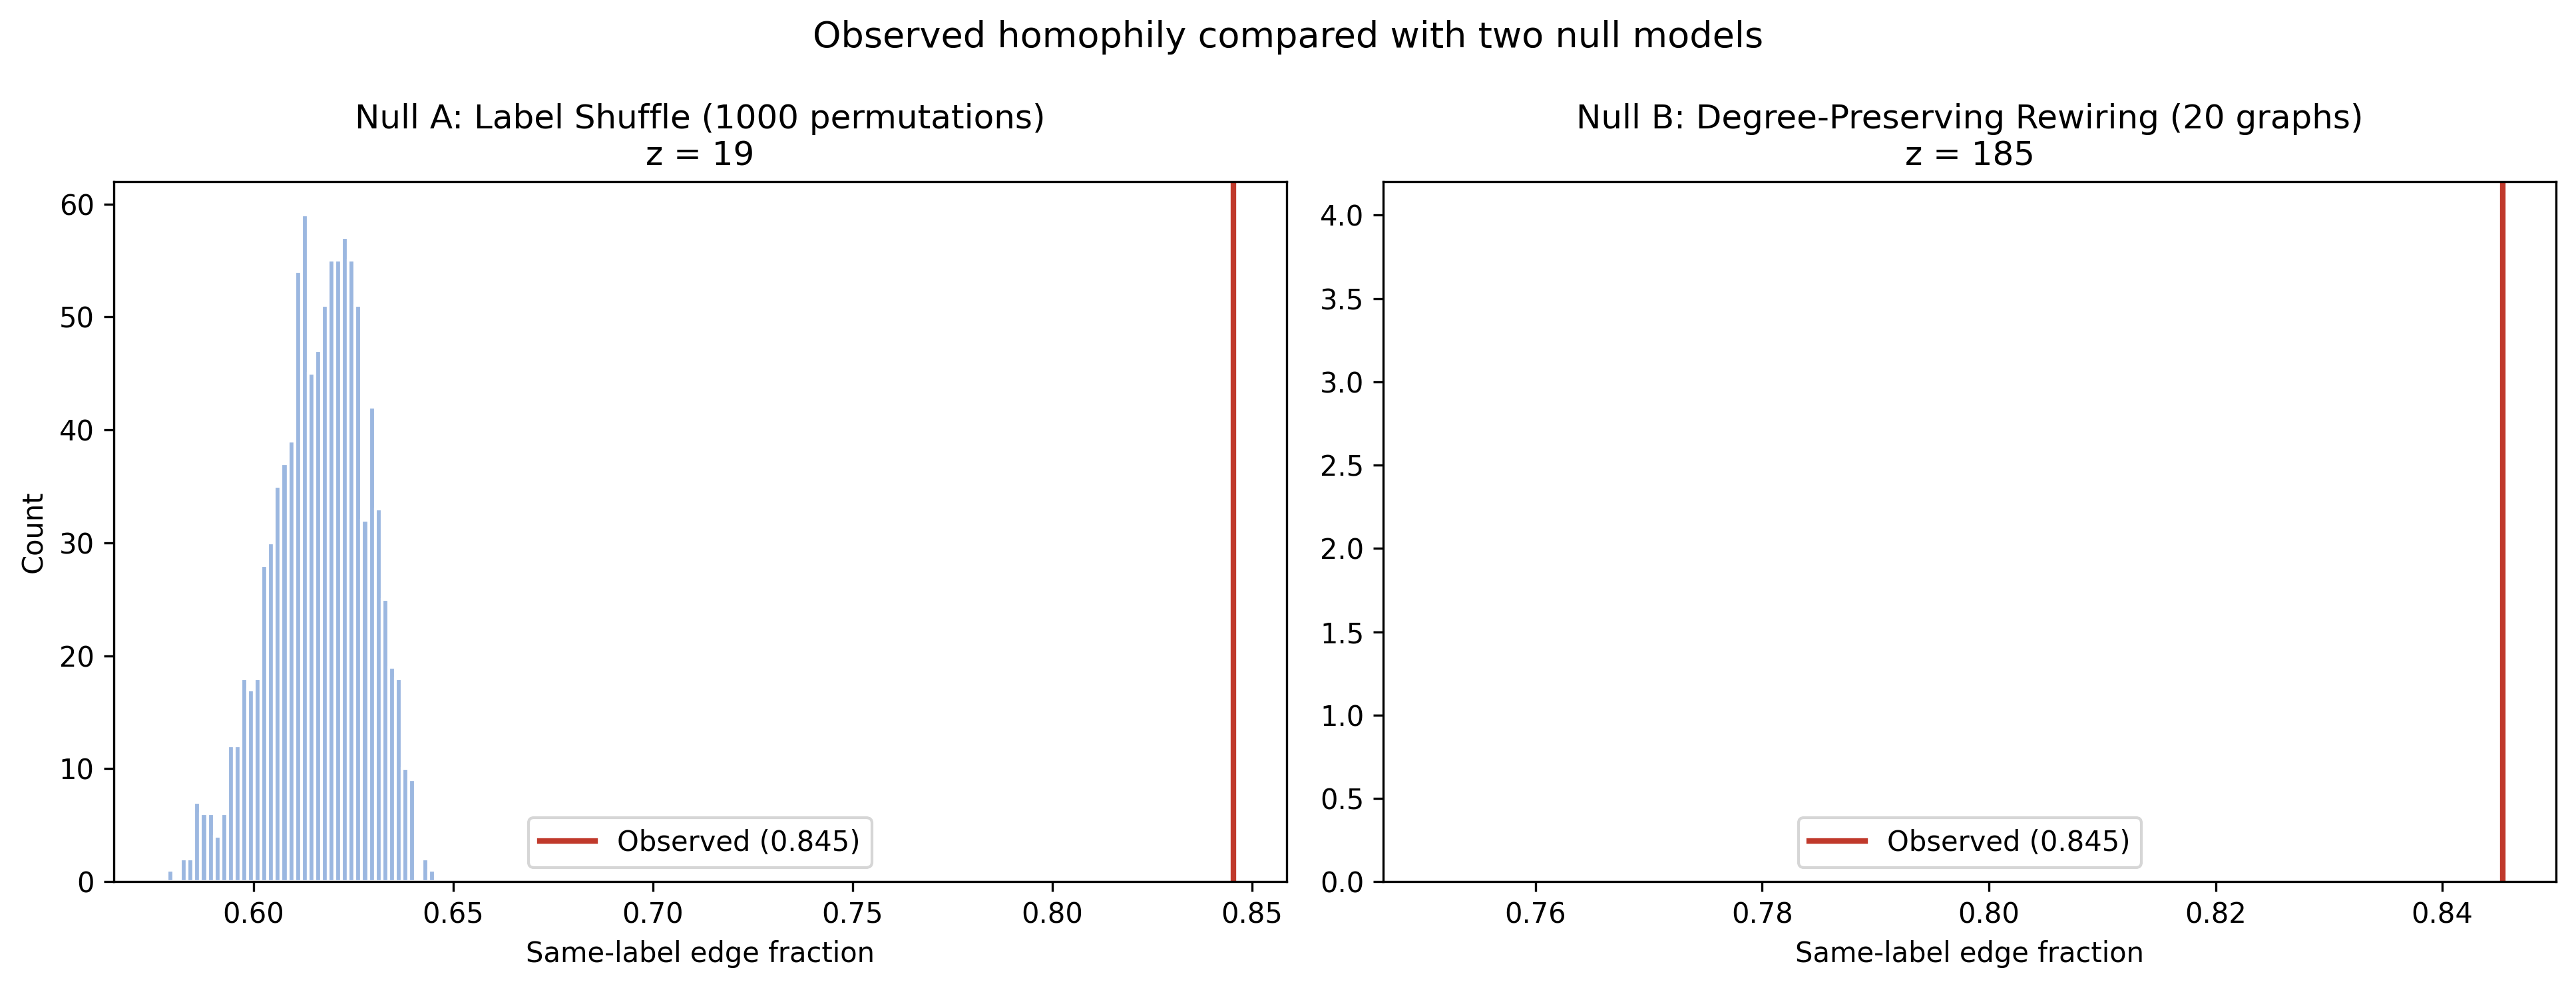

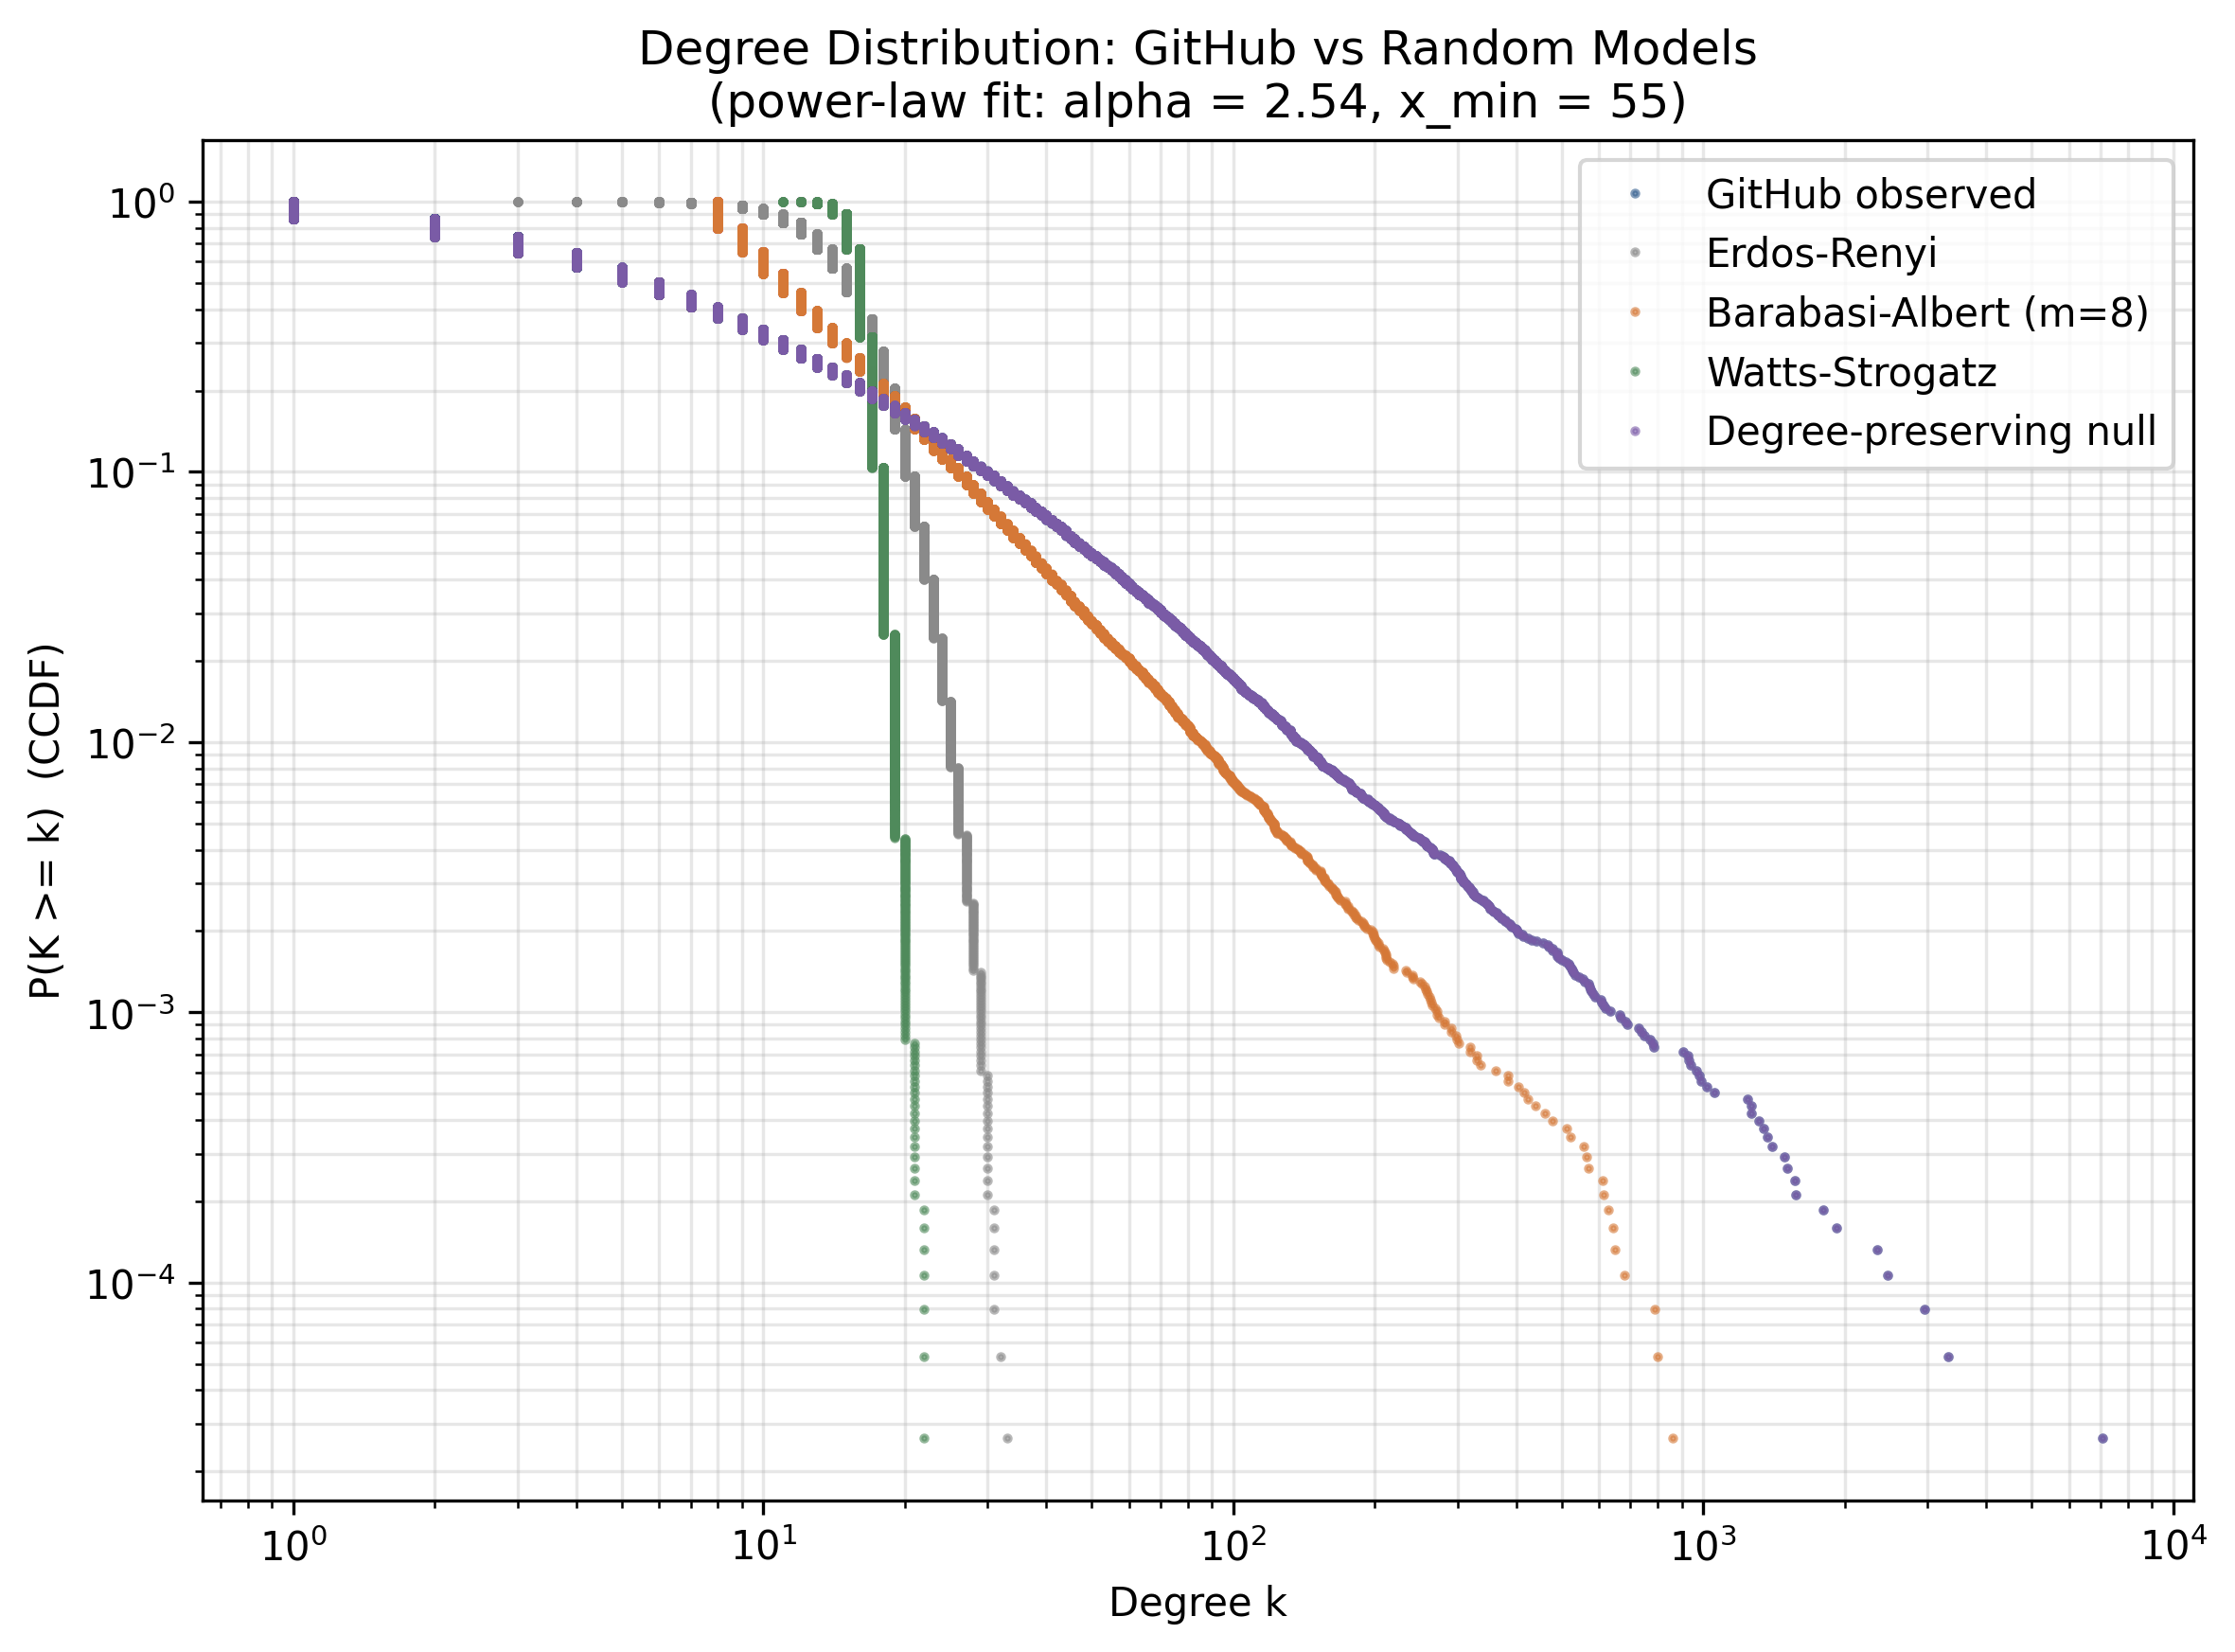

In [6]:
homophily_null = pd.read_csv(ROOT / "outputs/tables/null_model_homophily.csv")
modularity_null = pd.read_csv(ROOT / "outputs/tables/null_model_modularity.csv")
random_models = pd.read_csv(ROOT / "outputs/tables/network_vs_random_models.csv")
tail_fit = pd.read_csv(ROOT / "outputs/tables/powerlaw_fit.csv")

display(homophily_null.round(6))
display(modularity_null.round(6))
display(random_models.round(4))
display(tail_fit.round(4))
display(Image(filename=str(ROOT / "outputs/figures/homophily_null_distribution.png")))
display(Image(filename=str(ROOT / "outputs/figures/degree_distribution_loglog.png")))


Observed homophily is above all simulated values in both null experiments. The label-shuffle result has finer resolution because it uses 1,000 permutations. For degree-preserving rewiring, the empirical upper-tail p-value reaches the finite-simulation minimum of 0.0476, so the evidence is consistent with an upper-tail result but its numerical precision is limited. Observed modularity is also above the 20 rewired values with the same resolution limit.

The degree tail is heavy and a power law is favored over an exponential, but it is not clearly distinguishable from a lognormal alternative. A unique scale-free claim is therefore unsupported.

## Answers to the research questions


In [7]:
observed_homophily = float(homophily_null.loc[0, "observed"])
observed_modularity = float(modularity_null.loc[0, "observed_modularity"])
answers = pd.DataFrame([
    {
        "question": "RQ1 — Node classification",
        "answer": "Graph structure predicts developer field well, but not perfectly.",
        "evidence": "Best handcrafted graph ROC-AUC is near 0.869.",
    },
    {
        "question": "RQ2 — Network versus content",
        "answer": "Content and graph structure provide complementary predictive information.",
        "evidence": "Content is near 0.889 ROC-AUC; the hybrid is about 0.898; the strongest embedding combination is near 0.900.",
    },
    {
        "question": "RQ3 — Static edge reconstruction",
        "answer": "Randomly hidden edges can be reconstructed, but the same-field advantage is not universal.",
        "evidence": "Preferential Attachment is strongest overall at about 0.924 ROC-AUC.",
    },
    {
        "question": "RQ4 — Null models",
        "answer": "Observed homophily and modularity lie above the tested null distributions.",
        "evidence": f"Homophily={observed_homophily:.3f}; modularity={observed_modularity:.3f}; rewired-null p-value resolution is 1/21.",
    },
])
display(answers)


,question,answer,evidence
0,RQ1 — Node classification,"Graph structure predicts developer field well,...",Best handcrafted graph ROC-AUC is near 0.869.
1,RQ2 — Network versus content,Content and graph structure provide complement...,Content is near 0.889 ROC-AUC; the hybrid is a...
2,RQ3 — Static edge reconstruction,"Randomly hidden edges can be reconstructed, bu...",Preferential Attachment is strongest overall a...
3,RQ4 — Null models,Observed homophily and modularity lie above th...,Homophily=0.845; modularity=0.453; rewired-nul...


Together, these results support a strong relationship between developer field and network structure in this dataset. They do not establish causality.

## Limitations

The data are a static 2019 snapshot with a binary and potentially noisy target. Betweenness is approximated, embedding budgets are fixed, edge reconstruction is not temporal, random non-edge sampling may favor degree-based scores, and 20 rewired graphs provide only coarse empirical p-value resolution.

## Summary

This Notebook tested whether the observed homophily and community structure were unusual under 1,000 label shuffles and 20 connected degree-preserving rewires. Observed same-label edge fraction was 0.8453, compared with label-shuffle mean 0.6166 (z = 19.44, empirical p = 0.000999) and rewired mean 0.7513 (z = 179.08, empirical p = 0.0476).

Observed Louvain modularity was 0.4534, far above the rewired mean of 0.1885 (z = 340.36, empirical p = 0.0476). Both rewiring p-values reached the minimum possible value for 20 simulations, so they support an upper-tail result but cannot provide finer numerical significance.

Comparisons with Erd?s-R?nyi, Barab?si-Albert, Watts-Strogatz, and a degree-preserving configuration null showed that the GitHub graph combines extreme hubs, short sampled paths, and more clustering than simple random or preferential-attachment comparisons. The fitted degree tail had alpha 2.544 above xmin 55 and strongly favored a power law over an exponential, but it was not distinguishable from a lognormal alternative (p = 0.7826), so a unique scale-free conclusion was not supported.

Together with the earlier experiments, the Notebook consolidated the research answers: handcrafted graph classification reached about 0.869 ROC-AUC, combined representations reached about 0.900, static reconstruction reached about 0.924, and observed homophily and modularity exceeded the tested nulls. These results support a strong association between developer field and network structure in this static dataset, while the binary target, sampling choices, transductive setting, and finite rewiring budget limit broader claims.
